In [1]:
import sys
print(sys.executable)
print(sys.version)

/usr/local/bin/python3
3.14.6 (v3.14.6:c63aec69bd5, Jun 10 2026, 08:07:54) [Clang 21.0.0 (clang-2100.1.1.101)]


In [2]:
%pip install xgboost

Note: you may need to restart the kernel to use updated packages.


In [3]:
import xgboost
print(xgboost.__version__)

3.4.1


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.ensemble import ExtraTreesRegressor

from xgboost import XGBRegressor

In [5]:
df = pd.read_csv("BIKE DETAILS.csv")

df.head()

,name,selling_price,year,seller_type,owner,km_driven,ex_showroom_price
0,Royal Enfield Classic 350,175000,2019,Individual,1st owner,350,NaN
1,Honda Dio,45000,2017,Individual,1st owner,5650,NaN
2,Royal Enfield Classic Gunmetal Grey,150000,2018,Individual,1st owner,12000,148114.0
3,Yamaha Fazer FI V 2.0 [2016-2018],65000,2015,Individual,1st owner,23000,89643.0
4,Yamaha SZ [2013-2014],20000,2011,Individual,2nd owner,21000,NaN


In [6]:
print("Shape:", df.shape)

print("\nColumns:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

print("\nMissing Values:")
print(df.isnull().sum())

Shape: (1061, 7)

Columns:
['name', 'selling_price', 'year', 'seller_type', 'owner', 'km_driven', 'ex_showroom_price']

Data Types:
name                     str
selling_price          int64
year                   int64
seller_type              str
owner                    str
km_driven              int64
ex_showroom_price    float64
dtype: object

Missing Values:
name                   0
selling_price          0
year                   0
seller_type            0
owner                  0
km_driven              0
ex_showroom_price    435
dtype: int64


In [7]:
df.describe(include="all")

,name,selling_price,year,seller_type,owner,km_driven,ex_showroom_price
count,1061,1061.000000,1061.000000,1061,1061,1061.000000,6.260000e+02
unique,279,NaN,NaN,2,4,NaN,NaN
top,Bajaj Pulsar 150,NaN,NaN,Individual,1st owner,NaN,NaN
freq,41,NaN,NaN,1055,924,NaN,NaN
mean,NaN,59638.151744,2013.867107,NaN,NaN,34359.833176,8.795871e+04
std,NaN,56304.291973,4.301191,NaN,NaN,51623.152702,7.749659e+04
min,NaN,5000.000000,1988.000000,NaN,NaN,350.000000,3.049000e+04
25%,NaN,28000.000000,2011.000000,NaN,NaN,13500.000000,5.485200e+04
50%,NaN,45000.000000,2015.000000,NaN,NaN,25000.000000,7.275250e+04
75%,NaN,70000.000000,2017.000000,NaN,NaN,43000.000000,8.703150e+04


In [8]:
print("Duplicates before:", df.duplicated().sum())

df = df.drop_duplicates()

print("Duplicates after:", df.duplicated().sum())

Duplicates before: 6
Duplicates after: 0


In [9]:
df["year"] = pd.to_numeric(df["year"], errors="coerce")
df["km_driven"] = pd.to_numeric(df["km_driven"], errors="coerce")
df["ex_showroom_price"] = pd.to_numeric(df["ex_showroom_price"], errors="coerce")
df["selling_price"] = pd.to_numeric(df["selling_price"], errors="coerce")

In [10]:
df = df.dropna(subset=["selling_price"])

print(df.shape)

(1055, 7)


In [11]:
df["name"] = df["name"].fillna("Unknown")
df["seller_type"] = df["seller_type"].fillna("Unknown")
df["owner"] = df["owner"].fillna("Unknown")

In [12]:
df["bike_age"] = 2026 - df["year"]

df["km_per_year"] = df["km_driven"] / (df["bike_age"] + 1)

df["log_km_driven"] = np.log1p(df["km_driven"])

In [13]:
df["ex_showroom_price"] = df.groupby("name")["ex_showroom_price"].transform(
    lambda x: x.fillna(x.median())
)

df["ex_showroom_price"] = df["ex_showroom_price"].fillna(
    df["ex_showroom_price"].median()
)

df["log_ex_showroom"] = np.log1p(df["ex_showroom_price"])

print(df.isnull().sum())

name                 0
selling_price        0
year                 0
seller_type          0
owner                0
km_driven            0
ex_showroom_price    0
bike_age             0
km_per_year          0
log_km_driven        0
log_ex_showroom      0
dtype: int64


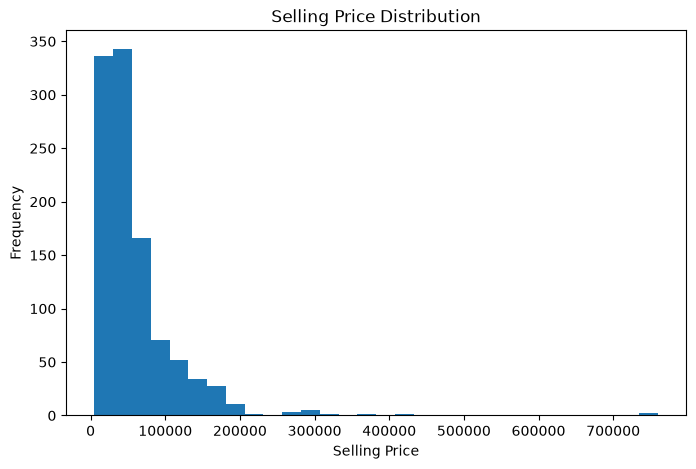

In [14]:
plt.figure(figsize=(8,5))
plt.hist(df["selling_price"], bins=30)
plt.xlabel("Selling Price")
plt.ylabel("Frequency")
plt.title("Selling Price Distribution")
plt.show()

In [15]:
X = df.drop(columns=["selling_price"])

y = df["selling_price"]

print("Features:", X.shape)
print("Target:", y.shape)

Features: (1055, 10)
Target: (1055,)


In [16]:
categorical_features = [
    "name",
    "seller_type",
    "owner"
]

numeric_features = [
    "year",
    "km_driven",
    "ex_showroom_price",
    "bike_age",
    "km_per_year",
    "log_km_driven",
    "log_ex_showroom"
]

In [17]:
numeric_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median"))
    ]
)

categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

In [18]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 844
Testing samples: 211


In [19]:
models = {
    "Linear Regression": LinearRegression(),

    "Random Forest": RandomForestRegressor(
        n_estimators=500,
        max_depth=None,
        min_samples_split=2,
        min_samples_leaf=1,
        max_features=0.8,
        random_state=42,
        n_jobs=-1
    ),

    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=500,
        learning_rate=0.03,
        max_depth=4,
        min_samples_split=2,
        min_samples_leaf=1,
        loss="huber",
        random_state=42
    ),

    "Extra Trees": ExtraTreesRegressor(
        n_estimators=500,
        max_depth=None,
        min_samples_split=2,
        min_samples_leaf=1,
        max_features=0.8,
        random_state=42,
        n_jobs=-1
    ),

    "XGBoost": XGBRegressor(
        n_estimators=1000,
        learning_rate=0.03,
        max_depth=5,
        min_child_weight=2,
        subsample=0.85,
        colsample_bytree=0.85,
        reg_alpha=0.05,
        reg_lambda=1,
        objective="reg:squarederror",
        random_state=42,
        n_jobs=-1
    )
}

In [20]:
results = []

trained_models = {}

for name, model in models.items():

    pipeline = Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("model", model)
        ]
    )

    pipeline.fit(X_train, y_train)

    predictions = pipeline.predict(X_test)

    r2 = r2_score(y_test, predictions)
    mae = mean_absolute_error(y_test, predictions)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))

    results.append({
        "Model": name,
        "R2 Score": r2,
        "MAE": mae,
        "RMSE": rmse
    })

    trained_models[name] = pipeline

In [21]:
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="R2 Score",
    ascending=False
)

results_df

,Model,R2 Score,MAE,RMSE
4,XGBoost,0.915850,11711.616211,19180.114702
2,Gradient Boosting,0.834027,13059.244413,26936.546360
0,Linear Regression,0.768098,18007.361325,31840.203773
3,Extra Trees,0.761719,13762.493384,32275.137753
1,Random Forest,0.726175,13901.890367,34598.727426


In [22]:
for _, row in results_df.iterrows():
    print(
        f"{row['Model']}: "
        f"R² = {row['R2 Score']:.4f}"
    )

XGBoost: R² = 0.9158
Gradient Boosting: R² = 0.8340
Linear Regression: R² = 0.7681
Extra Trees: R² = 0.7617
Random Forest: R² = 0.7262


In [23]:
best_model_name = results_df.iloc[0]["Model"]

best_model = trained_models[best_model_name]

print("Best Model:", best_model_name)

print(
    "Best R²:",
    round(results_df.iloc[0]["R2 Score"], 4)
)

Best Model: XGBoost
Best R²: 0.9158


In [24]:
final_predictions = best_model.predict(X_test)

final_r2 = r2_score(y_test, final_predictions)

final_mae = mean_absolute_error(y_test, final_predictions)

final_rmse = np.sqrt(
    mean_squared_error(y_test, final_predictions)
)

print("Final Model:", best_model_name)
print("R² Score:", round(final_r2, 4))
print("MAE:", round(final_mae, 2))
print("RMSE:", round(final_rmse, 2))

Final Model: XGBoost
R² Score: 0.9158
MAE: 11711.62
RMSE: 19180.11


In [25]:
comparison = pd.DataFrame({
    "Actual Price": y_test.values,
    "Predicted Price": final_predictions
})

comparison["Difference"] = (
    comparison["Actual Price"] -
    comparison["Predicted Price"]
)

comparison.head(20)

,Actual Price,Predicted Price,Difference
0,260000,253003.796875,6996.203125
1,60000,55806.035156,4193.964844
2,50000,51774.695312,-1774.695312
3,50000,54873.679688,-4873.679688
4,30000,46218.863281,-16218.863281
5,45000,36246.171875,8753.828125
6,75000,43150.867188,31849.132812
7,72000,88295.765625,-16295.765625
8,70000,57077.632812,12922.367188
9,28700,26388.347656,2311.652344


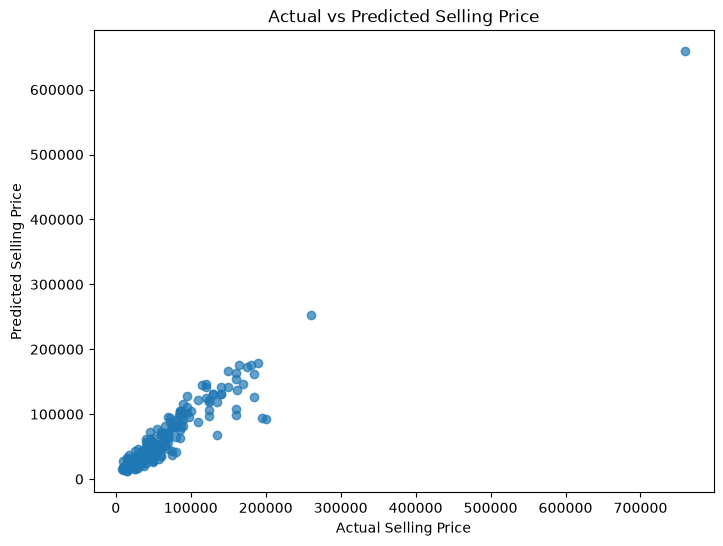

In [26]:
plt.figure(figsize=(8,6))

plt.scatter(
    y_test,
    final_predictions,
    alpha=0.7
)

plt.xlabel("Actual Selling Price")
plt.ylabel("Predicted Selling Price")
plt.title("Actual vs Predicted Selling Price")

plt.show()

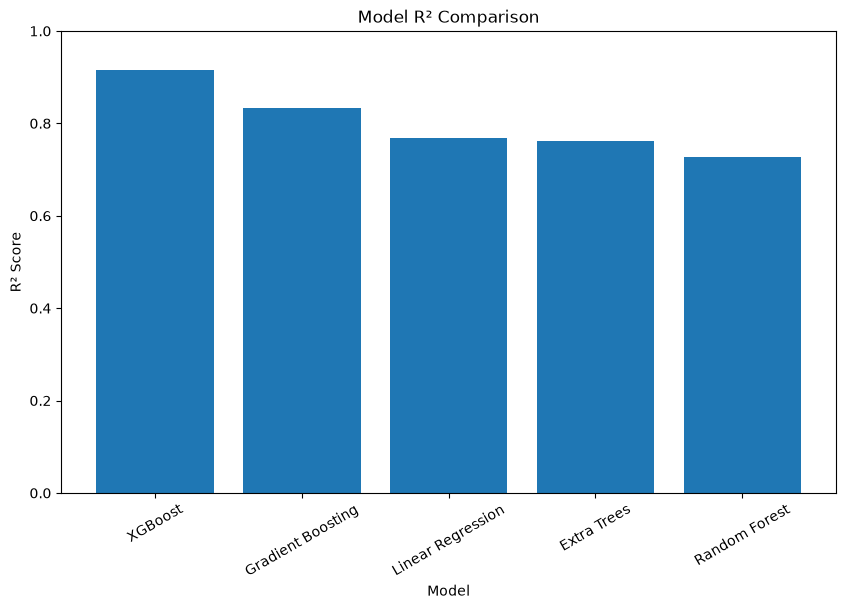

In [27]:
plt.figure(figsize=(10,6))

plt.bar(
    results_df["Model"],
    results_df["R2 Score"]
)

plt.xlabel("Model")
plt.ylabel("R² Score")
plt.title("Model R² Comparison")

plt.xticks(rotation=30)

plt.ylim(0, 1)

plt.show()

In [28]:
print("=" * 50)
print("BIKE PRICE PREDICTION")
print("=" * 50)
print("Best Model:", best_model_name)
print("R² Score:", round(final_r2, 4))
print("MAE:", round(final_mae, 2))
print("RMSE:", round(final_rmse, 2))
print("=" * 50)

BIKE PRICE PREDICTION
Best Model: XGBoost
R² Score: 0.9158
MAE: 11711.62
RMSE: 19180.11
